# Wine Quality Prediction: data preparation, EDA and model selection

**Problem.** Will a wine be rated *good* (taster score >= 6 out of 10) based on 11 laboratory measurements and the wine type (red / white)?
The model is meant as a cheap pre-screening tool for wineries: batches with a low probability of being good can be sent to a human expert for a closer look.

**Plan of this notebook**
1. Load and check the data
2. Clean the data and split it into train and test
3. Exploratory data analysis (EDA) and feature importance (training data only)
4. Compare several models with cross-validation
5. Tune the hyperparameters
6. Evaluate the final model once on the test set

The final training code lives in `train.py`; this notebook documents how the model was chosen.
Run it from the project root so that `data_prep.py` can be imported.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from data_prep import FEATURES, TARGET, load_and_clean, split_data
from train import BEST_PARAMS, evaluate, train

SEED = 1

## 1. Load and check the raw data

In [2]:
raw = pd.read_csv("data/wine_quality.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
print("Wine types:", raw["type"].value_counts().to_dict())
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Rows with at least one missing value:", int(raw.isna().any(axis=1).sum()))
print("\nMissing values per column (only columns with gaps):")
print(raw.isna().sum()[lambda s: s > 0].to_string())

Wine types: {'white': 4898, 'red': 1599}
Exact duplicate rows: 1168
Rows with at least one missing value: 34

Missing values per column (only columns with gaps):
fixed acidity       10
volatile acidity     8
citric acid          3
residual sugar       2
chlorides            2
pH                   9
sulphates            4


The raw file has **1168 exact duplicate rows** and **38 missing cells** (in 34 rows).

Decisions:
- **Duplicates are removed.** If the same wine ends up in both the training and the validation part, the scores look better than they really are (data leakage).
- **Missing values are filled with the median of the training data inside the model pipeline.** They are not filled here, because using the median of the whole dataset would leak information from validation/test data.
- `type` becomes a numeric feature `is_red` (1 = red, 0 = white).
- Target: `good = 1` if `quality >= 6`. The score `quality` itself is never used as a feature.

## 2. Clean the data and split it

In [4]:
df = load_and_clean()
print("Shape after cleaning:", df.shape)

# 80% for training/selection, 20% test set that stays untouched until the very end
df_full_train, df_test = split_data(df)
print("train:", df_full_train.shape, "| test:", df_test.shape)
print("Share of good wines -> train:", round(df_full_train[TARGET].mean(), 3), "| test:", round(df_test[TARGET].mean(), 3))

Shape after cleaning: (5329, 14)
train: (4263, 14) | test: (1066, 14)
Share of good wines -> train: 0.626 | test: 0.627


## 3. Exploratory data analysis (training data only)

All analysis below uses only the training part, so nothing is learned from the test set.
For the EDA we fill the few missing values with the training medians.

In [5]:
eda = df_full_train.copy()
train_medians = eda[FEATURES].median()
eda[FEATURES] = eda[FEATURES].fillna(train_medians)

### 3.1 Target variable

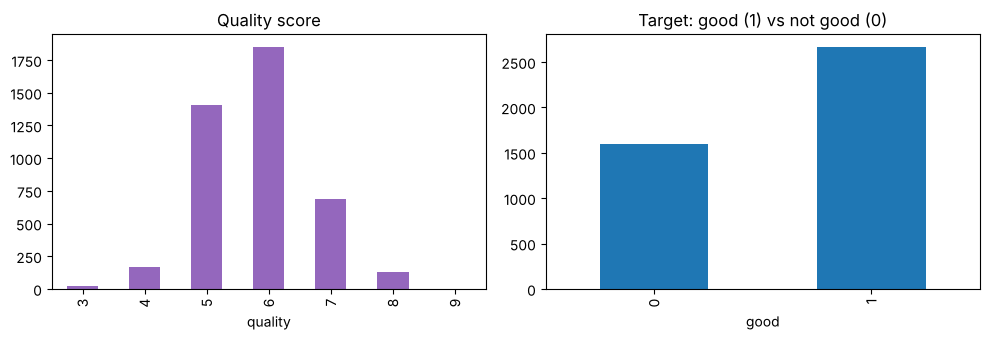

Share of good wines: 0.626

Share of good wines by type:
        count   mean
is_red              
white    3181  0.658
red      1082  0.533


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
eda.quality.value_counts().sort_index().plot.bar(ax=ax[0], color="tab:purple")
ax[0].set_title("Quality score")
eda[TARGET].value_counts().sort_index().plot.bar(ax=ax[1], color="tab:blue")
ax[1].set_title("Target: good (1) vs not good (0)")
plt.tight_layout()
plt.show()
print("Share of good wines:", round(eda[TARGET].mean(), 3))
print("\nShare of good wines by type:")
print(eda.groupby("is_red")[TARGET].agg(["count", "mean"]).rename(index={0: "white", 1: "red"}).round(3))

About 63% of the wines are good, so the classes are only moderately imbalanced and ROC AUC is a suitable main metric. White wines are rated good more often (about 66%) than red wines (about 53%).

### 3.2 Ranges and outliers

In [7]:
print(eda[FEATURES].describe().T[["min", "mean", "max"]].round(3).to_string())

                        min     mean      max
fixed_acidity         3.800    7.208   15.900
volatile_acidity      0.080    0.343    1.580
citric_acid           0.000    0.320    1.660
residual_sugar        0.600    5.093   65.800
chlorides             0.009    0.056    0.610
free_sulfur_dioxide   1.000   30.162  289.000
total_sulfur_dioxide  6.000  114.670  440.000
density               0.987    0.995    1.039
ph                    2.720    3.224    4.010
sulphates             0.220    0.534    2.000
alcohol               8.000   10.547   14.900
is_red                0.000    0.254    1.000


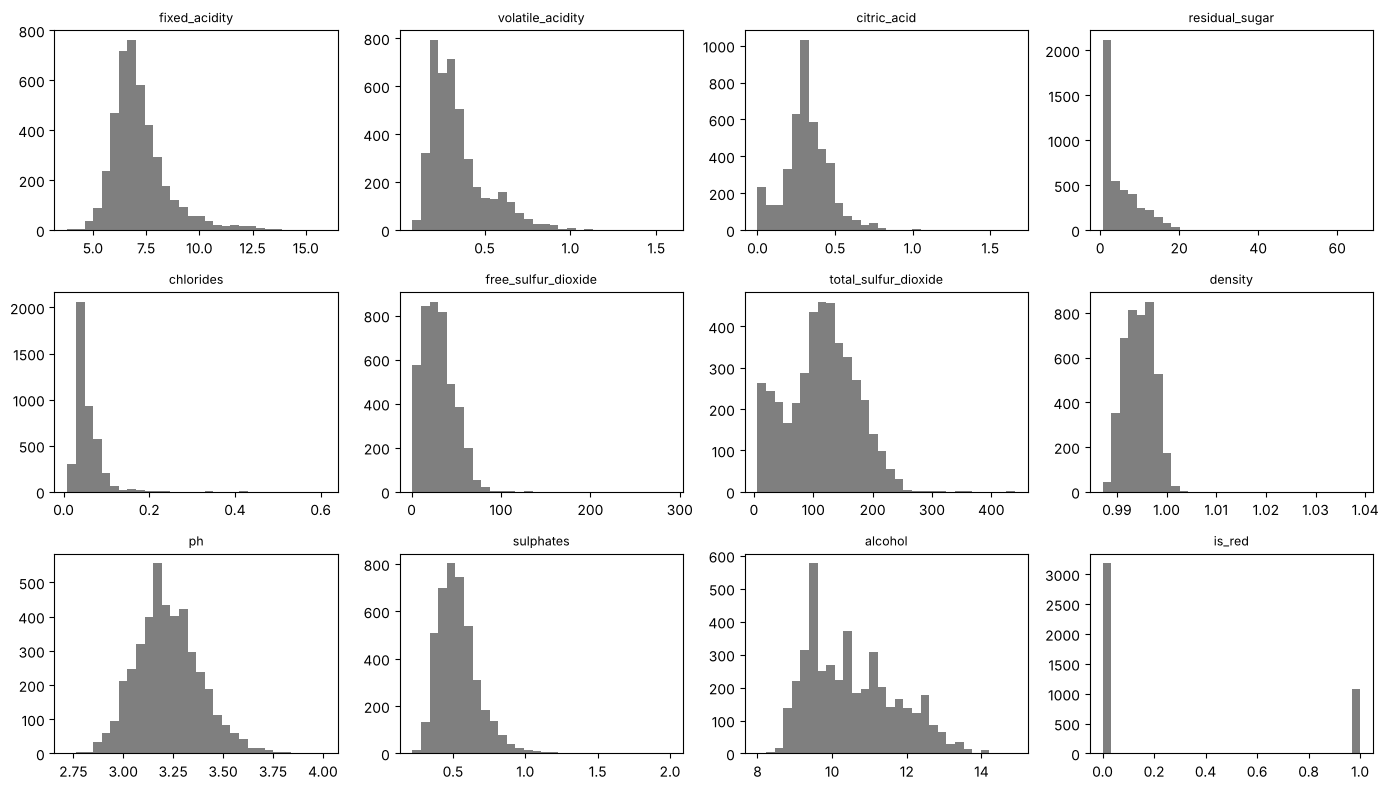

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    ax.hist(eda[col], bins=30, color="tab:gray")
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
# Outliers by the 1.5 * IQR rule
for col in [f for f in FEATURES if f != "is_red"]:
    q1, q3 = eda[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((eda[col] < q1 - 1.5 * iqr) | (eda[col] > q3 + 1.5 * iqr)).sum())
    print(f"{col:22s} {n_out:4d}")

fixed_acidity           238
volatile_acidity        210
citric_acid             296
residual_sugar          113
chlorides               181
free_sulfur_dioxide      38
total_sulfur_dioxide     12
density                   2
ph                       41
sulphates               135
alcohol                   1


Several features (e.g. `residual_sugar`, `chlorides`, `total_sulfur_dioxide`) are skewed and have many outliers. They are real measurements, so they are **kept**. Tree-based models are not sensitive to them, and the logistic regression uses scaling.

### 3.3 Feature importance

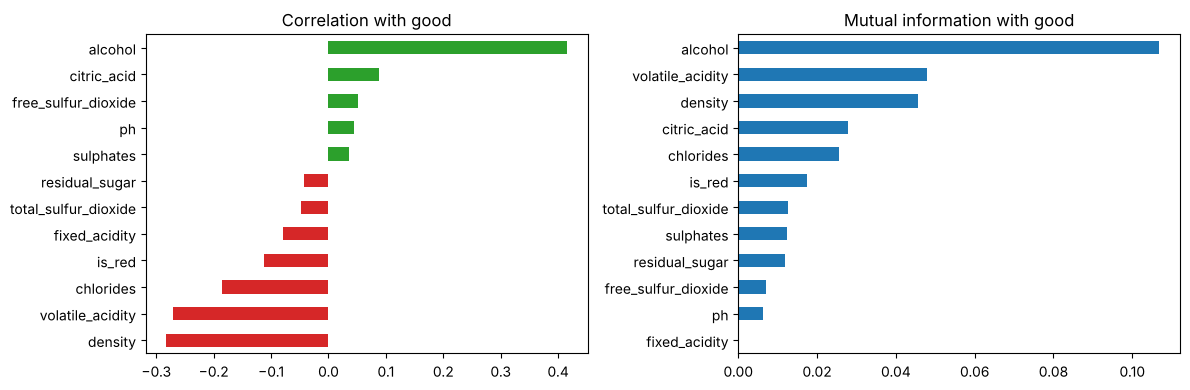

                      correlation  mutual_info
alcohol                     0.416        0.107
volatile_acidity           -0.271        0.048
density                    -0.283        0.046
citric_acid                 0.087        0.028
chlorides                  -0.185        0.026
is_red                     -0.112        0.017
total_sulfur_dioxide       -0.047        0.013
sulphates                   0.036        0.012
residual_sugar             -0.043        0.012
free_sulfur_dioxide         0.051        0.007
ph                          0.044        0.006
fixed_acidity              -0.079        0.000


In [10]:
corr = eda[FEATURES].corrwith(eda[TARGET]).sort_values()
mi = pd.Series(
    mutual_info_classif(eda[FEATURES], eda[TARGET], random_state=SEED), index=FEATURES
).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
corr.plot.barh(ax=ax[0], color=np.where(corr > 0, "tab:green", "tab:red"))
ax[0].set_title("Correlation with good")
mi.sort_values().plot.barh(ax=ax[1], color="tab:blue")
ax[1].set_title("Mutual information with good")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"correlation": corr, "mutual_info": mi}).sort_values("mutual_info", ascending=False).round(3))

- `alcohol` is by far the most important feature: better wines contain more alcohol.
- `density` and `volatile_acidity` (acetic acid, gives a vinegar taste) are the next ones; higher values go with worse wines.
- `sulphates`, which mattered a lot in red wine alone, is almost unimportant in the combined data. The relationship between features and quality is not the same for red and white wines, which is a hint that non-linear / tree-based models may work better.

### 3.4 Relations between the features

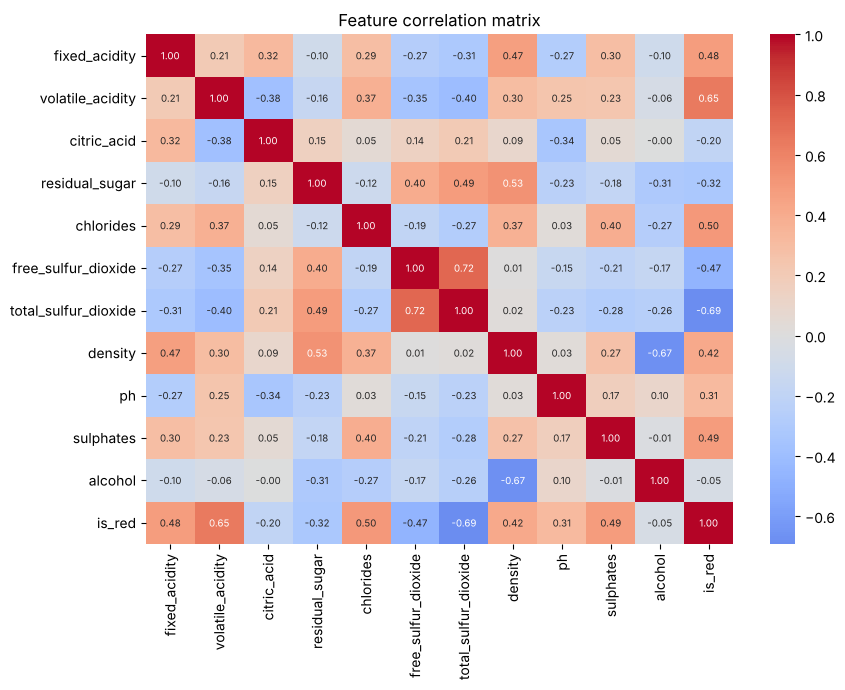

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(eda[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()

Some features are strongly related to each other (`free_sulfur_dioxide` vs `total_sulfur_dioxide`, `density` vs `alcohol`, `total_sulfur_dioxide` vs `is_red`). This multicollinearity makes the coefficients of a linear model less stable; tree-based models are not affected.

## 4. Model comparison with cross-validation

- Metric: **ROC AUC** with **5-fold stratified cross-validation** on the training data. The same folds are used for every model.
- Imputation (median) and scaling are inside a `Pipeline`, so in every fold they are learned from the training part of that fold only.
- Models: a dummy baseline, logistic regression (linear), random forest and XGBoost (tree-based).

In [12]:
X = df_full_train[FEATURES]
y = df_full_train[TARGET].values

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
impute = SimpleImputer(strategy="median")

models = {
    "dummy (always majority class)": DummyClassifier(strategy="prior"),
    "logistic regression": make_pipeline(impute, StandardScaler(), LogisticRegression(max_iter=1000)),
    "random forest": make_pipeline(impute, RandomForestClassifier(random_state=SEED, n_jobs=2)),
    "xgboost": make_pipeline(impute, XGBClassifier(random_state=SEED, n_jobs=2, eval_metric="logloss")),
}

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    rows.append({"model": name, "stage": "default", "auc_mean": scores.mean(), "auc_std": scores.std()})
    print(f"{name:30s} AUC = {scores.mean():.4f} +- {scores.std():.4f}")

dummy (always majority class)  AUC = 0.5000 +- 0.0000


logistic regression            AUC = 0.8096 +- 0.0154


random forest                  AUC = 0.8378 +- 0.0074


xgboost                        AUC = 0.8167 +- 0.0094


## 5. Hyperparameter tuning

`RandomizedSearchCV` tries a fixed number of random parameter combinations (15 / 20 / 30), which is much faster than trying all combinations.
This cell takes about 2-3 minutes.

In [13]:
searches = {
    "logistic regression": (
        make_pipeline(impute, StandardScaler(), LogisticRegression(max_iter=2000)),
        {"logisticregression__C": loguniform(1e-3, 1e2)},
        15,
    ),
    "random forest": (
        make_pipeline(impute, RandomForestClassifier(random_state=SEED, n_jobs=2)),
        {
            "randomforestclassifier__n_estimators": [100, 200, 300, 500],
            "randomforestclassifier__max_depth": [None, 8, 12, 16, 20],
            "randomforestclassifier__min_samples_leaf": [1, 2, 3, 5],
            "randomforestclassifier__max_features": ["sqrt", 0.5, 0.7],
        },
        20,
    ),
    "xgboost": (
        make_pipeline(impute, XGBClassifier(random_state=SEED, n_jobs=2, eval_metric="logloss")),
        {
            "xgbclassifier__n_estimators": [100, 200, 300, 500],
            "xgbclassifier__max_depth": [3, 4, 5, 6, 8],
            "xgbclassifier__learning_rate": [0.02, 0.05, 0.1, 0.2],
            "xgbclassifier__min_child_weight": [1, 3, 5],
            "xgbclassifier__subsample": [0.7, 0.85, 1.0],
            "xgbclassifier__colsample_bytree": [0.6, 0.8, 1.0],
        },
        30,
    ),
}

best_params = {}
for name, (pipe, grid, n_iter) in searches.items():
    search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1)
    search.fit(X, y)
    std = search.cv_results_["std_test_score"][search.best_index_]
    rows.append({"model": name, "stage": "tuned", "auc_mean": search.best_score_, "auc_std": std})
    best_params[name] = {k.split("__")[1]: v for k, v in search.best_params_.items()}
    print(f"{name:22s} best AUC = {search.best_score_:.4f} +- {std:.4f}")
    print("   best params:", best_params[name])

logistic regression    best AUC = 0.8096 +- 0.0154
   best params: {'C': np.float64(2.6674574591455764)}


random forest          best AUC = 0.8402 +- 0.0090
   best params: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}


xgboost                best AUC = 0.8385 +- 0.0113
   best params: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


In [14]:
results = pd.DataFrame(rows).round(4)
summary = results.pivot(index="model", columns="stage", values="auc_mean")[["default", "tuned"]]
summary

stage,default,tuned
model,,
dummy (always majority class),0.5000,NaN
logistic regression,0.8096,0.8096
random forest,0.8378,0.8402
xgboost,0.8167,0.8385


**Conclusions**
- The tree-based models (AUC about 0.84) are clearly better than logistic regression (about 0.81). The relationship between the lab values and quality is non-linear and differs between red and white wines.
- **Random forest and XGBoost are practically tied**: their difference (about 0.002) is much smaller than the standard deviation across folds (about 0.01).
- **Random forest is selected**: it has the highest mean score and needs only scikit-learn for deployment.
- Tuning helped XGBoost the most (0.817 -> 0.839).

## 6. Final model and evaluation on the test set

The final random forest (parameters from the search above, stored in `train.py`) is trained on the whole training part and evaluated **once** on the test set.

In [15]:
print("Parameters used in train.py:", BEST_PARAMS)
print("Parameters found in this notebook:", best_params["random forest"])

Parameters used in train.py: {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Parameters found in this notebook: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}


In [16]:
final_model = train(df_full_train)
print("train:", evaluate(final_model, df_full_train))
print("test: ", evaluate(final_model, df_test))

train: {'roc_auc': 0.9997, 'accuracy': 0.9862, 'n_rows': 4263}
test:  {'roc_auc': 0.8242, 'accuracy': 0.7542, 'n_rows': 1066}


The training score is almost perfect, which is normal for a random forest, so it says little. The **test score (ROC AUC about 0.82, accuracy about 0.75)** is the honest estimate for new wines. It is slightly lower than the cross-validation score, as expected, because the cross-validation data was also used to pick the parameters.

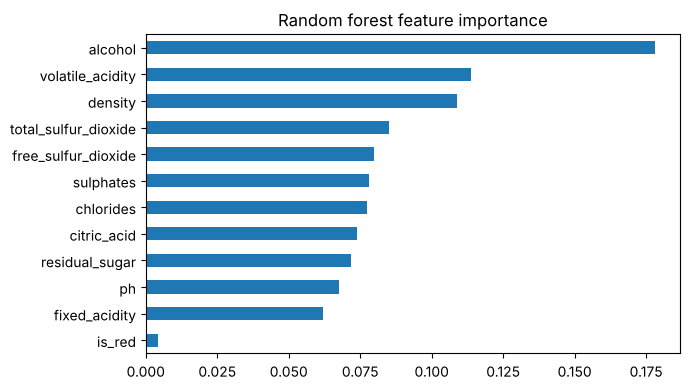

In [17]:
importances = pd.Series(
    final_model[-1].feature_importances_, index=FEATURES
).sort_values()
importances.plot.barh(figsize=(7, 4), color="tab:blue")
plt.title("Random forest feature importance")
plt.tight_layout()
plt.show()

The model relies mostly on `alcohol`, `density` and `volatile_acidity`, which agrees with the EDA.

## 7. Limitations and next steps
- The labels come from human tasters and are subjective; the model supports tasters, it does not replace them.
- Only Vinho Verde wines from Portugal are in the data; the model should not be used for other wines.
- Next steps: probability calibration, a custom threshold depending on the cost of missing a bad batch, more features.